# Lecture 1 Notebook

**Note:** In this example there is a lot of code. You are not expected to know how to read any of this yet. This is just a preview of the things you will see in the next few weeks. 


## This is a Jupyter Notebook

A Jupyter Notebook is a document that combines:

1. **Narrative:** The text describing your analysis
2. **Code:** The program that does the analysis
3. **Results:** The output of the program

The Jupyter environment was created by faculty here at Berkeley (Fernando Perez). These ideas are now in a lot of different technologies (e.g., Google Colab). 

## Our first example: analyzing the text of Little Women

*["Little Women"](https://en.wikipedia.org/wiki/Little_Women)* by Louisa May Alcott is the story of four sisters and their neighbor Laurie (Theodore Laurence).

To analyze it, we define a **function** that reads data from the Internet.

In [1]:
# A tiny program to download text from the web.
def read_url(url): 
    from urllib.request import urlopen 
    import re
    return re.sub('\\s+', ' ', urlopen(url).read().decode())

Here we download the book, which is hosted on the Data 8 textbook website.

In [2]:
little_women_url = 'https://www.inferentialthinking.com/data/little_women.txt'
little_women_text = read_url(little_women_url)
little_women_chapters = little_women_text.split('CHAPTER ')[1:]

## Tables

- A lot of data science is about transforming data. This is often in service of producing **tables**, a widely used data structure that we can more easily analyze our data with. 
- In this class you will use the `datascience` library (specifically created for this course) to manipulate and data.

In [3]:
# datascience
from datascience import *


In [4]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


In [5]:
# datascience
Table().with_column('Chapters', little_women_chapters)


Chapters
"ONE PLAYING PILGRIMS ""Christmas won't be Christmas witho ..."
TWO A MERRY CHRISTMAS Jo was the first to wake in the gr ...
"THREE THE LAURENCE BOY ""Jo! Jo! Where are you?"" cried Me ..."
"FOUR BURDENS ""Oh, dear, how hard it does seem to take up ..."
"FIVE BEING NEIGHBORLY ""What in the world are you going t ..."
SIX BETH FINDS THE PALACE BEAUTIFUL The big house did pr ...
"SEVEN AMY'S VALLEY OF HUMILIATION ""That boy is a perfect ..."
"EIGHT JO MEETS APOLLYON ""Girls, where are you going?"" as ..."
"NINE MEG GOES TO VANITY FAIR ""I do think it was the most ..."
"TEN THE P.C. AND P.O. As spring came on, a new set of am ..."


In [6]:
# polars
pl.DataFrame([
    pl.Series('Chapters', little_women_chapters)
])


Chapters
str
"""ONE PLAYING PILGRIMS ""Christma…"
"""TWO A MERRY CHRISTMAS Jo was t…"
"""THREE THE LAURENCE BOY ""Jo! Jo…"
"""FOUR BURDENS ""Oh, dear, how ha…"
"""FIVE BEING NEIGHBORLY ""What in…"
…
"""FORTY-THREE SURPRISES Jo was a…"
"""FORTY-FOUR MY LORD AND LADY ""P…"
"""FORTY-FIVE DAISY AND DEMI I ca…"


## We will learn to visualize data

Most notebooks contain some setup for data manipulation and visualization. The details aren't important, but an LM can tell you about them.

In [7]:
# datascience
from datascience import *
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)


In [8]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


We can calculate the number of times Jo was mentioned in each chapter.

In [9]:
# datascience
np.char.count(little_women_chapters, 'Jo')


array([44, 21, 62, 34, 55, 13,  9, 71, 21, 12, 42, 60, 24, 48, 26, 13, 29,
       35,  5, 29, 67, 17, 51, 36, 12, 17, 28, 69, 49, 39,  7, 60,  2, 55,
       42, 35,  5, 47, 15, 15, 17, 36, 61,  9,  6, 56, 37])

In [10]:
# polars
pl.Series('text', little_women_chapters).str.count_matches('Jo', literal=True)


text
u32
44
21
62
34
55
…
61
9
6


How about the other characters? We could build a table.

In [11]:
# datascience
# Counts of names in the chapters of Little Women

names = ['Amy', 'Beth', 'Jo', 'Meg', 'Laurie']
mentions = {name: np.char.count(little_women_chapters, name) for name in names}

counts = Table().with_columns([
        'Amy',    mentions['Amy'],
        'Beth',   mentions['Beth'],
        'Jo',     mentions['Jo'],
        'Meg',    mentions['Meg'],
        'Laurie', mentions['Laurie']
    ])
counts


Amy,Beth,Jo,Meg,Laurie
23,26,44,26,0
13,12,21,20,0
2,2,62,36,16
14,18,34,17,0
6,14,55,13,35
6,28,13,5,9
27,5,9,5,7
48,9,71,16,17
3,5,21,71,24
5,5,12,4,4


In [12]:
# polars
# Counts of names in the chapters of Little Women

names_pl = ['Amy', 'Beth', 'Jo', 'Meg', 'Laurie']
mentions_pl = {name: pl.Series('text', little_women_chapters).str.count_matches(name, literal=True) for name in names_pl}

counts_pl = pl.DataFrame([
    (mentions_pl['Amy']).alias('Amy'),
    (mentions_pl['Beth']).alias('Beth'),
    (mentions_pl['Jo']).alias('Jo'),
    (mentions_pl['Meg']).alias('Meg'),
    (mentions_pl['Laurie']).alias('Laurie')
])
counts_pl


Amy,Beth,Jo,Meg,Laurie
u32,u32,u32,u32,u32
23,26,44,26,0
13,12,21,20,0
2,2,62,36,16
14,18,34,17,0
6,14,55,13,35
…,…,…,…,…
31,8,61,3,29
13,0,9,0,10
1,2,6,2,0


We can accumulate the counts for each character to show the total in the book so far.

In [13]:
# datascience
cumulative_counts = Table()
for label in counts.labels:
    cumulative_counts = cumulative_counts.with_column(label, np.cumsum(counts.column(label)))
cumulative_counts


Amy,Beth,Jo,Meg,Laurie
23,26,44,26,0
36,38,65,46,0
38,40,127,82,16
52,58,161,99,16
58,72,216,112,51
64,100,229,117,60
91,105,238,122,67
139,114,309,138,84
142,119,330,209,108
147,124,342,213,112


In [14]:
# polars
cumulative_counts_pl = pl.DataFrame([
    counts_pl.get_column(label).cum_sum().alias(label)
    for label in counts_pl.columns
])
cumulative_counts_pl


Amy,Beth,Jo,Meg,Laurie
u32,u32,u32,u32,u32
23,26,44,26,0
36,38,65,46,0
38,40,127,82,16
52,58,161,99,16
58,72,216,112,51
…,…,…,…,…
619,459,1435,673,571
632,459,1444,673,581
633,461,1450,675,581


And then to study these numbers we can create a line chart of cumulative counts.

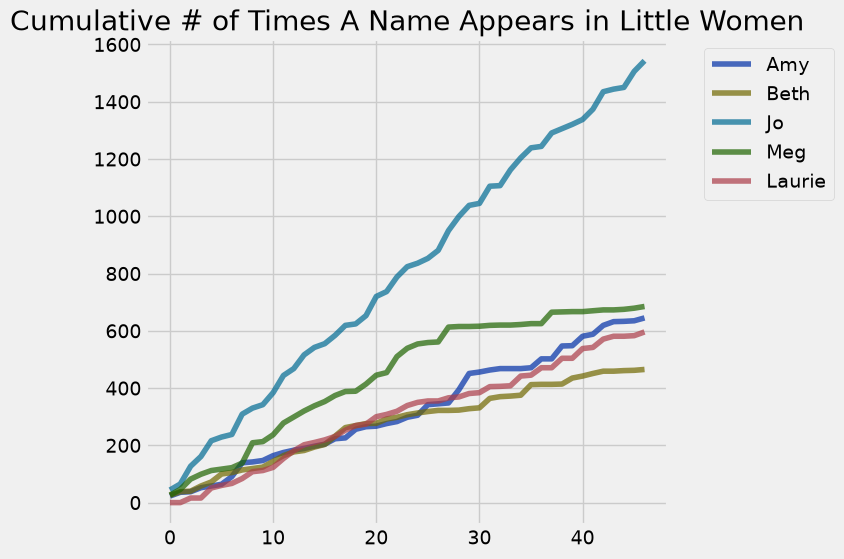

In [15]:
# datascience
cumulative_counts.plot()
plt.title('Cumulative # of Times A Name Appears in Little Women')
plt.show()


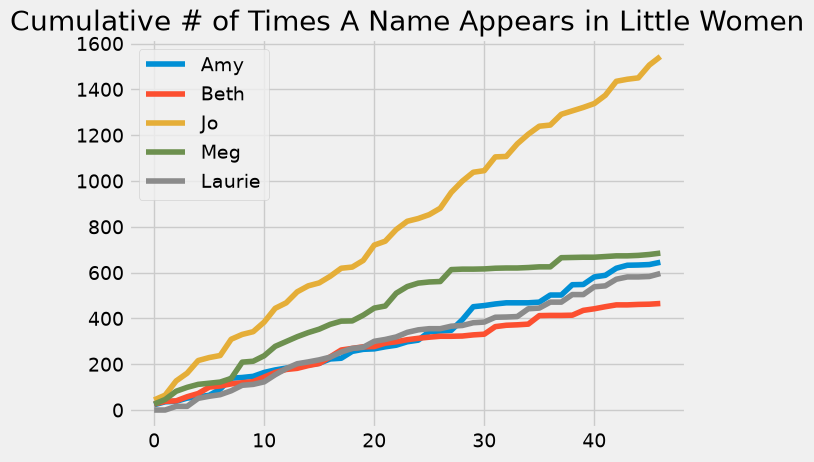

In [16]:
# polars
# matplotlib
for _col in cumulative_counts_pl.columns:
    plt.plot(cumulative_counts_pl.get_column(_col), label=_col)
plt.legend()
plt.title('Cumulative # of Times A Name Appears in Little Women')
plt.show()


Read the [book chapter](https://inferentialthinking.com/chapters/01/3/1/literary-characters/)!